# RTE 不同 FedSS 参数的准确率曲线

读取当前目录中的所有 CSV 文件，自动跳过文件开头的配置元数据，并绘制不同方法（参数）的 `round–accuracy` 曲线。

In [1]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd()
if not list(DATA_DIR.glob('*.csv')):
    DATA_DIR = Path('close-optimal-result/rte/dirichlet_0_4_10.yaml/test1')

csv_files = sorted(DATA_DIR.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'在 {DATA_DIR.resolve()} 中没有找到 CSV 文件')

print(f'数据目录: {DATA_DIR.resolve()}')
print(f'CSV 文件数: {len(csv_files)}')

数据目录: D:\vscode\CODES\paper_experiment_record\close-optimal-result\rte\dirichlet_0_4_10.yaml\test1
CSV 文件数: 10


In [2]:
def read_experiment_csv(csv_path):
    """自动定位包含 round 和 accuracy 的表头并读取数据。"""
    header_row = None
    with csv_path.open('r', encoding='utf-8-sig') as file:
        for index, line in enumerate(file):
            columns = [column.strip() for column in line.strip().split(',')]
            if 'round' in columns and 'accuracy' in columns:
                header_row = index
                break

    if header_row is None:
        raise ValueError('未找到包含 round 和 accuracy 的表头')

    frame = pd.read_csv(csv_path, skiprows=header_row)
    frame['round'] = pd.to_numeric(frame['round'], errors='coerce')
    frame['accuracy'] = pd.to_numeric(frame['accuracy'], errors='coerce')
    return frame.dropna(subset=['round', 'accuracy']).sort_values('round')


def method_label(filename):
    """从文件名提取方法；例如 fedss_01 -> FedSS 0.1。"""
    fedss_match = re.search(r'fedss_(\d{2,3})_dirichlet', filename, re.IGNORECASE)
    if fedss_match:
        token = fedss_match.group(1)
        value = int(token) / (10 if len(token) == 2 else 100)
        return f'FedSS {value:.1f}'

    for method in ('zeropadding', 'rbla', 'sp', 'flexlora'):
        if method in filename.lower():
            return method.replace('zeropadding', 'Zero-padding').upper() if method == 'rbla' else method.replace('zeropadding', 'Zero-padding').replace('flexlora', 'FlexLoRA').replace('sp', 'SP')

    return Path(filename).stem.split('_-train-')[0]


experiments = []
for csv_file in csv_files:
    try:
        frame = read_experiment_csv(csv_file)
        experiments.append({
            'label': method_label(csv_file.name),
            'file': csv_file.name,
            'data': frame,
        })
    except Exception as exc:
        print(f'跳过读取失败的文件 {csv_file.name}: {exc}')

if not experiments:
    raise RuntimeError('没有成功读取任何实验 CSV 文件')

pd.DataFrame([
    {'method': item['label'], 'file': item['file'], 'rounds': len(item['data'])}
    for item in experiments
]).sort_values('method')

,method,file,rounds
0,FedSS 0.1,rte_roberta_large_fedss_01_dirichlet_0_4_10_-t...,11
1,FedSS 0.2,rte_roberta_large_fedss_02_dirichlet_0_4_10_-t...,11
2,FedSS 0.3,rte_roberta_large_fedss_03_dirichlet_0_4_10_-t...,11
3,FedSS 0.4,rte_roberta_large_fedss_04_dirichlet_0_4_10_-t...,11
4,FedSS 0.5,rte_roberta_large_fedss_05_dirichlet_0_4_10_-t...,11
5,FedSS 0.6,rte_roberta_large_fedss_06_dirichlet_0_4_10_-t...,11
6,FedSS 0.7,rte_roberta_large_fedss_07_dirichlet_0_4_10_-t...,11
7,FedSS 0.8,rte_roberta_large_fedss_08_dirichlet_0_4_10_-t...,11
8,FedSS 0.9,rte_roberta_large_fedss_09_dirichlet_0_4_10_-t...,11
9,FedSS 1.0,rte_roberta_large_fedss_10_dirichlet_0_4_10_-t...,11


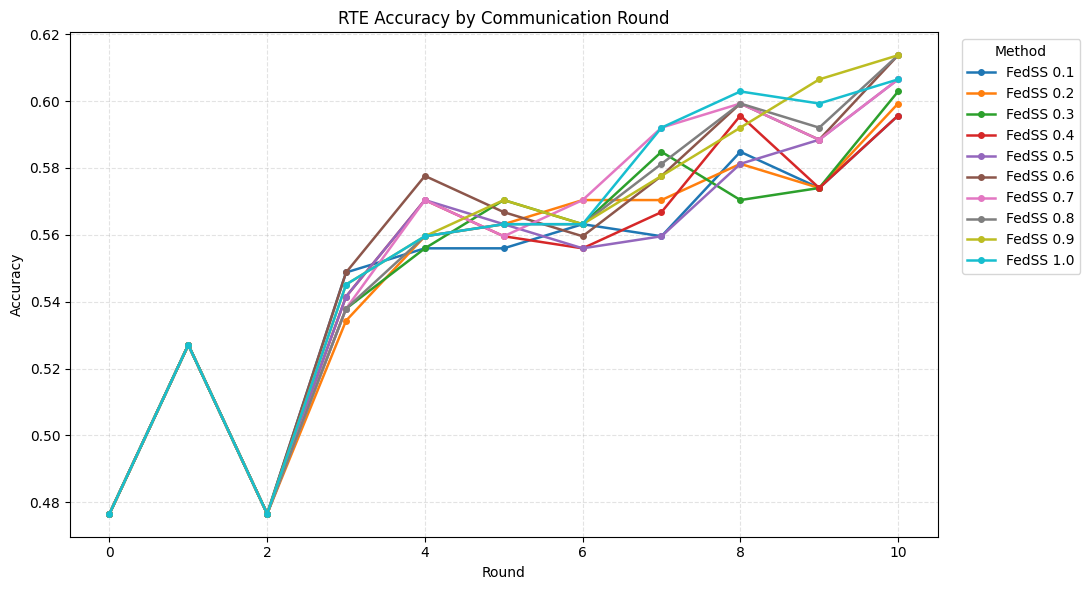

In [3]:
def label_sort_key(item):
    match = re.search(r'(\d+(?:\.\d+)?)$', item['label'])
    return (0, float(match.group(1))) if match else (1, item['label'])


fig, ax = plt.subplots(figsize=(11, 6))
for experiment in sorted(experiments, key=label_sort_key):
    frame = experiment['data']
    ax.plot(
        frame['round'], frame['accuracy'],
        marker='o', markersize=4, linewidth=1.8,
        label=experiment['label'],
    )

ax.set_xlabel('Round')
ax.set_ylabel('Accuracy')
ax.set_title('RTE Accuracy by Communication Round')
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend(title='Method', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()